# COS 802: Semantic Textual Similarity Across Domains
**Linda Masia (u21607363)**


## 1. Setup and config

In [ ]:
import os, re, csv, math, random, platform, zipfile, urllib.request, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from tqdm.auto import tqdm
from scipy.stats import spearmanr, pearsonr, rankdata

warnings.filterwarnings("ignore", category=FutureWarning)

# Mount Google Drive conditionally
from google.colab import drive
if not os.path.exists('/content/drive/MyDrive'):
    print("Mounting Google Drive...")
    drive.mount('/content/drive')
else:
    print("Google Drive is already mounted.")

PERSIST_DIR = '/content/drive/MyDrive/COS802_STS'
os.makedirs(PERSIST_DIR, exist_ok=True)
print(f"Data will be persisted to: {PERSIST_DIR}")

# ---------------- switches ----------------
QUICK = False            # True = smoke test (fewer bootstraps / seeds / train sizes)
RUN_SIMCSE = False       # optional unsupervised SimCSE-style extension (Section 6.4)

# ---------------- models ----------------
# Define missing constants
GLOVE_NAME = "glove-wiki-gigaword-50"
BERT_NAME = "bert-base-uncased"
SBERT_NAME = "all-MiniLM-L6-v2"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ---------------- experiment settings ----------------
N_BOOT      = 200 if QUICK else 1000
ADAPT_SEEDS = [0] if QUICK else [0, 1, 2]
ADAPT_SIZES = [100, 1000] if QUICK else [100, 250, 500, 1000, 2500, 5000, "full"]
ADAPT_EPOCHS, ADAPT_LR, ADAPT_BS, MARGIN = 3, 2e-5, 16, 0.5
fast_adapt_sizes = [100, 250, 500, 750, 1000]

POS_MIN_VOTES = 4
NEG_MAX_VOTES = 1

SEED = 2157
DATA_DIR, OUT_DIR = Path("data"), Path("results")
DATA_DIR.mkdir(exist_ok=True); OUT_DIR.mkdir(exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)
set_seed(SEED)
print("device:", DEVICE)


Google Drive is already mounted.
Data will be persisted to: /content/drive/MyDrive/COS802_STS
device: cuda


In [ ]:
%pip install -q sentence-transformers transformers datasets gensim scikit-learn scipy statsmodels pandas matplotlib tqdm

## 2. EDA


In [ ]:
import urllib.request
import zipfile
import io
import pandas as pd

from datasets import load_dataset
STSB = load_dataset("sentence-transformers/stsb")
BIOSSES = load_dataset("tabilab/biosses")

PIT_ZIP_URL = "https://raw.githubusercontent.com/cocoxu/SemEval-PIT2015/master/data/SemEval-PIT2015-github.zip"
PIT_COLS = ["topic_id", "topic", "s1", "s2", "label_raw", "tag1", "tag2"]

response = urllib.request.urlopen(PIT_ZIP_URL)
with zipfile.ZipFile(io.BytesIO(response.read())) as z:
    with z.open('SemEval-PIT2015-github/data/train.data') as f:
        PIT2015_train = pd.read_csv(f, sep='\t', names=PIT_COLS, header=None)
    with z.open('SemEval-PIT2015-github/data/test.data') as f:
        PIT2015_test = pd.read_csv(f, sep='\t', names=PIT_COLS[:-2], header=None)


README.md:   0%|          | 0.00/1.50k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  471kB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  142kB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  108kB            

... (4 outputs left out)

README.md:   0%|          | 0.00/6.75k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 23.1kB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/100 [00:00<?, ? examples/s]

In [ ]:
import pandas as pd
import ast
import numpy as np
import urllib.request
import zipfile
import io
import os
from datasets import Dataset, DatasetDict, load_from_disk

pit_path = os.path.join(PERSIST_DIR, 'PIT2015_norm')
stsb_path = os.path.join(PERSIST_DIR, 'STSB_norm')
biosses_path = os.path.join(PERSIST_DIR, 'BIOSSES_norm')

if os.path.exists(pit_path) and os.path.exists(stsb_path) and os.path.exists(biosses_path):
    print("Loading PIT-2015, STS-B, and BIOSSES from Google Drive...")
    PIT2015_norm = load_from_disk(pit_path)
    STSB_norm = load_from_disk(stsb_path)
    BIOSSES_norm = load_from_disk(biosses_path)
else:
    print("Processing datasets from scratch...")
    # 1. Correctly re-load PIT2015_test using all 7 columns to prevent column shifting
    response = urllib.request.urlopen(PIT_ZIP_URL)
    with zipfile.ZipFile(io.BytesIO(response.read())) as z:
        with z.open('SemEval-PIT2015-github/data/test.data') as f:
            PIT2015_test = pd.read_csv(f, sep='\t', names=PIT_COLS, header=None)

    # 2. Universal parsing function to support both tuple strings (train) and single integers (test)
    def parse_pit_score_universal(label_val):
        label_str = str(label_val).strip()
        try:
            # Attempt to parse as tuple e.g., '(3, 2)'
            val = ast.literal_eval(label_str)
            if isinstance(val, tuple) and len(val) == 2:
                yes_votes, no_votes = val
                total = yes_votes + no_votes
                return 5.0 * (yes_votes / total) if total > 0 else 0.0
        except Exception:
            pass

        # Attempt to parse as integer count of positive votes out of 5 (test format)
        try:
            val = float(label_str)
            return val # Already represents yes_votes out of 5.0 max
        except Exception:
            return np.nan

    # 3. Apply parsing to train and test sets
    PIT2015_train['score'] = PIT2015_train['label_raw'].apply(parse_pit_score_universal)
    PIT2015_test['score'] = PIT2015_test['label_raw'].apply(parse_pit_score_universal)

    # 4. Standardize columns
    pit_train_clean = PIT2015_train[['s1', 's2', 'score']].rename(columns={'s1': 'sentence1', 's2': 'sentence2'}).dropna()
    pit_test_clean = PIT2015_test[['s1', 's2', 'score']].rename(columns={'s1': 'sentence1', 's2': 'sentence2'}).dropna()

    # 5. Normalize all scores to [0.0, 1.0] range
    def keep_stsb_as_is(batch):
        return batch

    def normalize_biosses(batch):
        batch['score'] = [s / 4.0 for s in batch['score']]
        return batch

    # Normalize HF datasets
    STSB_norm = STSB.map(keep_stsb_as_is, batched=True)
    BIOSSES_norm = BIOSSES.map(normalize_biosses, batched=True)

    # Normalize PIT-2015 and convert to HF Dataset
    pit_train_clean['score'] = pit_train_clean['score'] / 5.0
    pit_test_clean['score'] = pit_test_clean['score'] / 5.0

    PIT2015_norm = DatasetDict({
        'train': Dataset.from_pandas(pit_train_clean, preserve_index=False),
        'test': Dataset.from_pandas(pit_test_clean, preserve_index=False)
    })

    print("Saving datasets to Google Drive...")
    PIT2015_norm.save_to_disk(pit_path)
    STSB_norm.save_to_disk(stsb_path)
    BIOSSES_norm.save_to_disk(biosses_path)

# Verify
print(f"PIT-2015 Train count: {len(PIT2015_norm['train'])} (Score Range: {min(PIT2015_norm['train']['score'])} to {max(PIT2015_norm['train']['score'])})")
print(f"STSB Train count: {len(STSB_norm['train'])} (Score Range: {min(STSB_norm['train']['score'])} to {max(STSB_norm['train']['score'])})")
print(f"BIOSSES Train count: {len(BIOSSES_norm['train'])} (Score Range: {min(BIOSSES_norm['train']['score'])} to {max(BIOSSES_norm['train']['score'])})")

Loading PIT-2015, STS-B, and BIOSSES from Google Drive...
PIT-2015 Train count: 13063 (Score Range: 0.0 to 1.0)
STSB Train count: 5749 (Score Range: 0.0 to 1.0)
BIOSSES Train count: 100 (Score Range: 0.0 to 1.0)


In [ ]:
from datasets import load_dataset, Dataset, DatasetDict, load_from_disk
import pandas as pd
import numpy as np
import os

finsts_path = os.path.join(PERSIST_DIR, 'FinSTS_norm')

if os.path.exists(finsts_path):
    print("Loading FinSTS from Google Drive...")
    FinSTS_norm = load_from_disk(finsts_path)
else:
    try:
        # Load the user-specified syang687/FinSTS dataset
        print("Loading syang687/FinSTS...")
        FinSTS_raw = load_dataset("syang687/FinSTS")

        # Normalize scores from [0.0, 5.0] range to [0.0, 1.0]
        def normalize_finsts(batch):
            batch['score'] = [float(s) / 5.0 for s in batch['score']]
            return batch

        FinSTS_norm = FinSTS_raw.map(normalize_finsts, batched=True)
        print("Successfully configured FinSTS (Financial Domain) with normalized scores!")

        print("Saving FinSTS to Google Drive...")
        FinSTS_norm.save_to_disk(finsts_path)
    except Exception as e:
        print("Could not configure FinSTS:", e)

# Display the dataset structures
print("\nBIOSSES Dataset structure:")
print(BIOSSES_norm)
print("\nSTSB Dataset structure:")
print(STSB_norm)
print("\nFinSTS Dataset structure:")
print(FinSTS_norm)
print("\nPIT-2015 Dataset structure:")
print(PIT2015_norm)

Loading FinSTS from Google Drive...

BIOSSES Dataset structure:
DatasetDict({
    train: Dataset({
        features: ['sentence1', 'sentence2', 'score'],
        num_rows: 100
    })
})

STSB Dataset structure:
DatasetDict({
    train: Dataset({
        features: ['sentence1', 'sentence2', 'score'],
        num_rows: 5749
    })
    validation: Dataset({
        features: ['sentence1', 'sentence2', 'score'],
        num_rows: 1500
    })
    test: Dataset({
        features: ['sentence1', 'sentence2', 'score'],
        num_rows: 1379
    })
})

FinSTS Dataset structure:
DatasetDict({
    validation: Dataset({
        features: ['split', 'sentence1', 'sentence2', 'gpt_score', 'score'],
        num_rows: 2001
    })
    test: Dataset({
        features: ['split', 'sentence1', 'sentence2', 'gpt_score', 'score'],
        num_rows: 1999
    })
})

PIT-2015 Dataset structure:
DatasetDict({
    train: Dataset({
        features: ['sentence1', 'sentence2', 'score'],
        num_rows: 13063
   

In [ ]:
# Inspect the first 10 pairs of the newly loaded syang687/FinSTS dataset
import pandas as pd

finsts_df = FinSTS_norm['test'].to_pandas()
print("First 10 rows of syang687/FinSTS showing sentences and normalized scores:")
display(finsts_df[['sentence1', 'sentence2', 'score']].head(10))

First 10 rows of syang687/FinSTS showing sentences and normalized scores:


,sentence1,sentence2,score
0,"For a more complete understanding of trends, e...",For a more complete understanding of the Compa...,0.8
1,We are subject to restrictive debt covenants w...,The senior secured credit facility contains af...,0.6
2,"However, any actuarial gains generated in futu...","There wasn't necessarily an additive, a mix ad...",0.0
3,In some cases these statements are identifiabl...,Such statements contain words such as ?€?belie...,0.6
4,There has been no change to the composition of...,"Yeah, your last question I believe was on sale...",0.0
5,In some cases these statements are identifiabl...,Forward-looking statements include the items i...,0.6
6,Among the significant changes resulting from t...,The TCJA provides for numerous significant tax...,0.6
7,"For important disclosures, please see the Morg...",For important personal holdings and research d...,0.8
8,Our desktop PC product brands for microprocess...,Our desktop PC product brands for microprocess...,0.6
9,"Under the terms of the agreement with Crown, t...","And as a follow-up if I could, can you make an...",0.0


In [ ]:
# Let's check the unique scores in the entire FinSTS test set
print("Frequency of each normalized score in the complete FinSTS test set:")
print(finsts_df['score'].value_counts().sort_index())

Frequency of each normalized score in the complete FinSTS test set:
score
0.0    687
0.2    167
0.4     72
0.6    362
0.8    385
1.0    326
Name: count, dtype: int64


In [ ]:
# Load the raw Hugging Face dataset and print the first 10 rows without any manipulation
from datasets import load_dataset

raw_finsts_test = load_dataset("FinanceMTEB/FinSTS", split="test")
print("First 10 raw rows from FinanceMTEB/FinSTS (Before Normalization):")
for idx in range(10):
    print(f"Row {idx}: {raw_finsts_test[idx]}")

README.md:   0%|          | 0.00/418 [00:00<?, ?B/s]

data/test-00000-of-00001-6c91fa192c582d4(…): reconstructing file:   0%|          |  0.00B / 81.0kB            

data/test-00000-of-00001-6c91fa192c582d4(…): downloading bytes:           |  0.00B            

Generating test split:   0%|          | 0/370 [00:00<?, ? examples/s]

First 10 raw rows from FinanceMTEB/FinSTS (Before Normalization):
Row 0: {'sentence1': 'We have undertaken, or will undertake, a variety of initiatives to integrate, standardize, centralize, and streamline our operations with technology, including, but not limited to, an enterprise resource planning system and a customer information and billing system.', 'sentence2': 'We have undertaken, and will continue to undertake, a variety of initiatives to integrate, standardize, centralize, and streamline our operations with technology, including, but not limited to, the implementation of several different ERP systems.', 'score': 1}
Row 1: {'sentence1': 'Any failures, negative publicity or lawsuits resulting from our administration of LIBOR or other benchmarks could result in a loss of confidence in the administration of these benchmarks and could harm our business and our reputation.', 'sentence2': "Any failures, negative publicity or lawsuits related to our subsidiaries' administration of ben

In [ ]:
import ast
import numpy as np

def parse_pit_score(label_str):
    try:
        # Convert string representation of tuple e.g., '(5, 0)' to tuple
        val = ast.literal_eval(str(label_str))
        if isinstance(val, tuple) and len(val) == 2:
            yes_votes, no_votes = val
            total = yes_votes + no_votes
            if total == 0:
                return 0.0
            # Calculate ratio of positive agreement (0 to 1), and scale to 0-5 range
            return 5.0 * (yes_votes / total)
    except Exception:
        pass
    return np.nan

# Let's apply this conversion and preview the scores
PIT2015_train['score'] = PIT2015_train['label_raw'].apply(parse_pit_score)
print("PIT-2015 Train with standardized 0-5 similarity scores:")
display(PIT2015_train[['s1', 's2', 'label_raw', 'score']].head())


PIT-2015 Train with standardized 0-5 similarity scores:


,s1,s2,label_raw,score
0,EJ Manuel the 1st QB to go in this draft,But my bro from the 757 EJ Manuel is the 1st Q...,"(5, 0)",5.0
1,EJ Manuel the 1st QB to go in this draft,Can believe EJ Manuel went as the 1st QB in th...,"(5, 0)",5.0
2,EJ Manuel the 1st QB to go in this draft,EJ MANUEL IS THE 1ST QB what,"(3, 2)",3.0
3,EJ Manuel the 1st QB to go in this draft,EJ da 1st QB off da board,"(2, 3)",2.0
4,EJ Manuel the 1st QB to go in this draft,Manuel is the 1st QB to get drafted,"(4, 1)",4.0


In [ ]:
import urllib.request
import zipfile
import io

# Let's inspect the raw lines of test.data to understand its structure and delimiter spacing
response = urllib.request.urlopen(PIT_ZIP_URL)
with zipfile.ZipFile(io.BytesIO(response.read())) as z:
    with z.open('SemEval-PIT2015-github/data/test.data') as f:
        raw_lines = [f.readline().decode('utf-8') for _ in range(10)]

print("Raw line previews from PIT-2015 test.data:")
for i, line in enumerate(raw_lines):
    print(f"Line {i}: {repr(line)}")


Raw line previews from PIT-2015 test.data:
Line 0: '51\t8 Mile\tAll the home alones watching 8 mile\t8 mile is on thats my movie\t3\tAll/O/DT/B-NP/O the/O/DT/I-NP/O home/O/NN/I-NP/O alones/O/VBZ/B-VP/O watching/O/VBG/I-VP/B-EVENT 8/O/CD/B-NP/O mile/O/NN/I-NP/O\t8/O/NN/B-NP/O mile/O/NN/I-NP/O is/O/VBZ/B-VP/O on/O/IN/B-PP/O thats/O/NNS/B-NP/O my/O/PRP$/B-NP/O movie/O/NN/I-NP/B-EVENT\n'
Line 1: '51\t8 Mile\tAll the home alones watching 8 mile\tThe last rap battle in 8 Mile nevr gets old ahah\t2\tAll/O/DT/B-NP/O the/O/DT/I-NP/O home/O/NN/I-NP/O alones/O/VBZ/B-VP/O watching/O/VBG/I-VP/B-EVENT 8/O/CD/B-NP/O mile/O/NN/I-NP/O\tThe/O/DT/B-NP/O last/O/JJ/I-NP/O rap/O/NN/I-NP/B-EVENT battle/O/NN/I-NP/B-EVENT in/O/IN/B-PP/O 8/O/CD/B-NP/O Mile/O/NNP/I-NP/O nevr/O/NN/I-NP/O gets/O/VBZ/B-VP/O old/O/JJ/B-NP/O ahah/O/JJ/I-NP/O\n'
Line 2: '51\t8 Mile\tAll the home alones watching 8 mile\tThe rap battle at the end of 8 mile gets me so hype\t2\tAll/O/DT/B-NP/O the/O/DT/I-NP/O home/O/NN/I-NP/O alones/O/VBZ

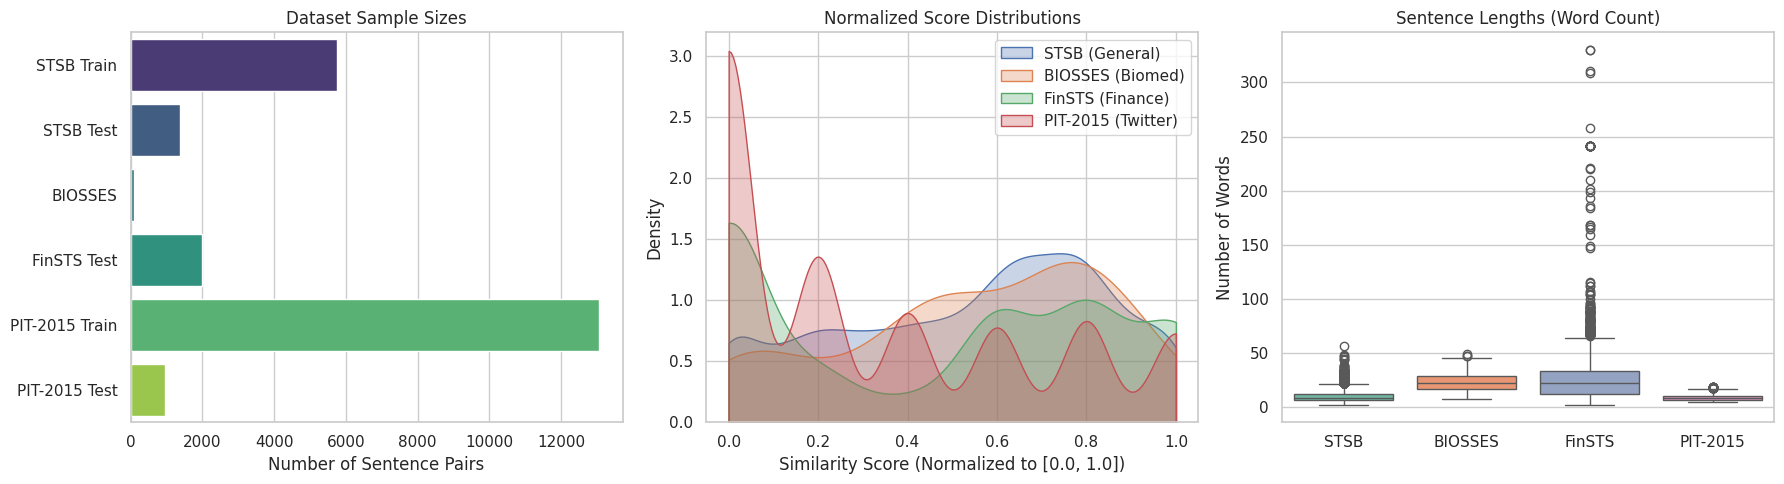


=== STSB (General Domain) Normalized Head ===


,sentence1,sentence2,score
0,A plane is taking off.,An air plane is taking off.,1.00
1,A man is playing a large flute.,A man is playing a flute.,0.76
2,A man is spreading shreded cheese on a pizza.,A man is spreading shredded cheese on an uncoo...,0.76
3,Three men are playing chess.,Two men are playing chess.,0.52
4,A man is playing the cello.,A man seated is playing the cello.,0.85



=== BIOSSES (Biomed Domain) Normalized Head ===


,sentence1,sentence2,score
0,"Here, looking for agents that could specifical...","Not surprisingly, GATA2 knockdown in KRAS muta...",0.55
1,MLL-FKBP and MLL-AF9 transformed cells showed ...,Regardless of the mechanism for transcriptiona...,0.80
2,The oncogenic activity of mutant Kras appears ...,Oncogenic KRAS mutations are common in cancer.,0.50
3,Consequently miRNAs have been demonstrated to ...,Given the extensive involvement of miRNA in ph...,0.70
4,We then sought to reassess the regulation of m...,"Importantly, our reassessment revealed that th...",0.60



=== FinSTS (Finance Domain) Normalized Head ===


,sentence1,sentence2,score
0,"For a more complete understanding of trends, e...",For a more complete understanding of the Compa...,0.8
1,We are subject to restrictive debt covenants w...,The senior secured credit facility contains af...,0.6
2,"However, any actuarial gains generated in futu...","There wasn't necessarily an additive, a mix ad...",0.0
3,In some cases these statements are identifiabl...,Such statements contain words such as ?€?belie...,0.6
4,There has been no change to the composition of...,"Yeah, your last question I believe was on sale...",0.0



=== PIT-2015 (Twitter Domain) Normalized Head ===


,sentence1,sentence2,score
0,EJ Manuel the 1st QB to go in this draft,But my bro from the 757 EJ Manuel is the 1st Q...,1.0
1,EJ Manuel the 1st QB to go in this draft,Can believe EJ Manuel went as the 1st QB in th...,1.0
2,EJ Manuel the 1st QB to go in this draft,EJ MANUEL IS THE 1ST QB what,0.6
3,EJ Manuel the 1st QB to go in this draft,EJ da 1st QB off da board,0.4
4,EJ Manuel the 1st QB to go in this draft,Manuel is the 1st QB to get drafted,0.8


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Configuration mapping for all datasets and domains
CONFIGS = [
    {"name": "STSB", "domain": "General", "dataset": STSB_norm, "split": "train", "color": "C0"},
    {"name": "BIOSSES", "domain": "Biomed", "dataset": BIOSSES_norm, "split": "train", "color": "C1"},
    {"name": "FinSTS", "domain": "Finance", "dataset": FinSTS_norm, "split": "test", "color": "C2"},
    {"name": "PIT-2015", "domain": "Twitter", "dataset": PIT2015_norm, "split": "train", "color": "C3"}
]

# Prepare figure
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Dataset Sizes (including test splits)
size_labels = ['STSB Train', 'STSB Test', 'BIOSSES', 'FinSTS Test', 'PIT-2015 Train', 'PIT-2015 Test']
sizes = [
    len(STSB_norm['train']),
    len(STSB_norm['test']),
    len(BIOSSES_norm['train']),
    len(FinSTS_norm['test']),
    len(PIT2015_norm['train']),
    len(PIT2015_norm['test'])
]
sns.barplot(x=sizes, y=size_labels, ax=axes[0], palette="viridis", hue=size_labels, legend=False)
axes[0].set_title("Dataset Sample Sizes")
axes[0].set_xlabel("Number of Sentence Pairs")

# 2 & 3. Distributions and Sentence Lengths via loops
lens_data = []
for cfg in CONFIGS:
    data_split = cfg["dataset"][cfg["split"]]
    scores = [x['score'] for x in data_split]

    # Plot normalized score distribution
    sns.kdeplot(scores, ax=axes[1], label=f"{cfg['name']} ({cfg['domain']})", fill=True, alpha=0.3, clip=(0.0, 1.0))

    # Compute word counts
    wc = [len(x['sentence1'].split()) for x in data_split] + [len(x['sentence2'].split()) for x in data_split]
    lens_data.append(wc)

axes[1].set_title("Normalized Score Distributions")
axes[1].set_xlabel("Similarity Score (Normalized to [0.0, 1.0])")
axes[1].set_ylabel("Density")
axes[1].set_xlim(-0.05, 1.05)
axes[1].legend()

sns.boxplot(data=lens_data, ax=axes[2], palette="Set2")
axes[2].set_xticks(range(len(CONFIGS)))
axes[2].set_xticklabels([cfg["name"] for cfg in CONFIGS])
axes[2].set_title("Sentence Lengths (Word Count)")
axes[2].set_ylabel("Number of Words")

plt.tight_layout()
plt.show()

# --- Display DataFrame Heads elegantly using a loop ---
for cfg in CONFIGS:
    print(f"\n=== {cfg['name']} ({cfg['domain']} Domain) Normalized Head ===")
    data_split = cfg["dataset"][cfg["split"]]
    display(data_split.to_pandas()[['sentence1', 'sentence2', 'score']].head(5))

## 3. Model


In [ ]:
!pip install -q gensim

import re
import numpy as np
import pandas as pd
import torch
from transformers import AutoTokenizer, AutoModel
from sentence_transformers import SentenceTransformer
import gensim.downloader as gensim_api

WORD_RE = re.compile(r"[a-z0-9]+(?:['\-][a-z0-9]+)*")
def words(s): return WORD_RE.findall(s.lower())

class GloveEncoder:
    name = "GloVe"
    def __init__(self):
        self.kv = gensim_api.load(GLOVE_NAME); self.dim = self.kv.vector_size
    def encode(self, sents):
        out = np.zeros((len(sents), self.dim), dtype=np.float32)
        for i, s in enumerate(sents):
            vecs = [self.kv[w] for w in words(s) if w in self.kv]
            if vecs: out[i] = np.mean(vecs, axis=0)
        return out

class BertMeanEncoder:
    name = "BERT"
    def __init__(self, model_name=BERT_NAME, batch_size=64, max_len=128):
        self.tok = AutoTokenizer.from_pretrained(model_name)
        self.model = AutoModel.from_pretrained(model_name).to(DEVICE).eval()
        self.bs, self.max_len = batch_size, max_len
    @torch.no_grad()
    def encode(self, sents):
        out = []
        for i in range(0, len(sents), self.bs):
            b = self.tok(sents[i:i + self.bs], padding=True, truncation=True,
                         max_length=self.max_len, return_tensors="pt").to(DEVICE)
            h = self.model(**b).last_hidden_state
            m = b["attention_mask"].unsqueeze(-1).float()
            out.append(((h * m).sum(1) / m.sum(1).clamp(min=1e-9)).cpu().numpy())
        return np.vstack(out)

class SBertEncoder:
    name = "SBERT"
    def __init__(self, model=None):
        self.model = model if model is not None else SentenceTransformer(SBERT_NAME, device=str(DEVICE))
    def encode(self, sents):
        return self.model.encode(sents, batch_size=64, convert_to_numpy=True, show_progress_bar=False)

def pair_cosine(encoder, df):
    sents = pd.unique(pd.concat([df.s1, df.s2])).tolist()
    E = encoder.encode(sents); idx = {s: i for i, s in enumerate(sents)}
    A, B = E[[idx[s] for s in df.s1]], E[[idx[s] for s in df.s2]]
    return (A * B).sum(1) / (np.linalg.norm(A, axis=1) * np.linalg.norm(B, axis=1) + 1e-12)

ENCODERS = {"GloVe": GloveEncoder(), "BERT": BertMeanEncoder(), "SBERT": SBertEncoder()}


[==================================================] 100.0% 66.0/66.0MB downloaded


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

... (12 outputs left out)

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

In [ ]:
# Include FinSTS in the global evaluation sets
EVAL_SETS = {
    "STS-B": STSB_norm["test"],
    "BIOSSES": BIOSSES_norm["train"],
    "FinSTS": FinSTS_norm["test"],
    "PIT-2015": PIT2015_norm["test"]
}

DOMAIN = {
    "STS-B": "general",
    "BIOSSES": "biomedical",
    "FinSTS": "financial",
    "PIT-2015": "social media"
}

## 4. Zero-shot evaluation (RQ1, RQ4)
• RQ1: How well do pretrained sentence embeddings generalize across general, biomedical, financial, and social media STS datasets?
• RQ4: Do GloVe, BERT, and Sentence-BERT show different sensitivity to domain shift?


In [ ]:
def bootstrap_corr(y, p, n_boot=N_BOOT, seed=0, kind="spearman"):
    f = (lambda a, b: spearmanr(a, b)[0]) if kind == "spearman" else (lambda a, b: pearsonr(a, b)[0])
    rng = np.random.default_rng(seed); y, p = np.asarray(y), np.asarray(p); n = len(y)
    vals = np.empty(n_boot)
    for i in range(n_boot):
        idx = rng.integers(0, n, n); vals[i] = f(y[idx], p[idx])
    return vals

def ci(vals): return tuple(np.percentile(vals, [2.5, 97.5]))

SIMS, BOOT, rows = {}, {}, []
for mname, enc in ENCODERS.items():
    for dname, d in EVAL_SETS.items():
        df_eval = d.to_pandas().rename(columns={"sentence1": "s1", "sentence2": "s2"})
        sims = pair_cosine(enc, df_eval); SIMS[(mname, dname)] = sims
        rho, r = spearmanr(df_eval.score, sims)[0], pearsonr(df_eval.score, sims)[0]
        BOOT[(mname, dname)] = bootstrap_corr(df_eval.score, sims)
        lo, hi = ci(BOOT[(mname, dname)])
        rows.append(dict(model=mname, dataset=dname, domain=DOMAIN[dname], n=len(d),
                         spearman=rho, ci_lo=lo, ci_hi=hi, pearson=r))
zs = pd.DataFrame(rows)
zs.round(3)

,model,dataset,domain,n,spearman,ci_lo,ci_hi,pearson
0,GloVe,STS-B,general,1379,0.413,0.365,0.461,0.370
1,GloVe,BIOSSES,biomedical,100,0.311,0.118,0.489,0.215
2,GloVe,FinSTS,financial,1999,0.800,0.783,0.813,0.664
3,GloVe,PIT-2015,social media,972,0.237,0.177,0.297,0.214
4,BERT,STS-B,general,1379,0.473,0.429,0.513,0.479
5,BERT,BIOSSES,biomedical,100,0.545,0.406,0.666,0.533
6,BERT,FinSTS,financial,1999,0.800,0.783,0.815,0.879
7,BERT,PIT-2015,social media,972,0.457,0.403,0.507,0.477
8,SBERT,STS-B,general,1379,0.820,0.799,0.842,0.827
9,SBERT,BIOSSES,biomedical,100,0.813,0.716,0.879,0.841


### Zero-Shot Evaluation Performance Visualizations
Below we visualize the performance metrics (Spearman and Pearson correlation coefficients) computed for each pre-trained sentence embedding encoder across the four target evaluation domains.

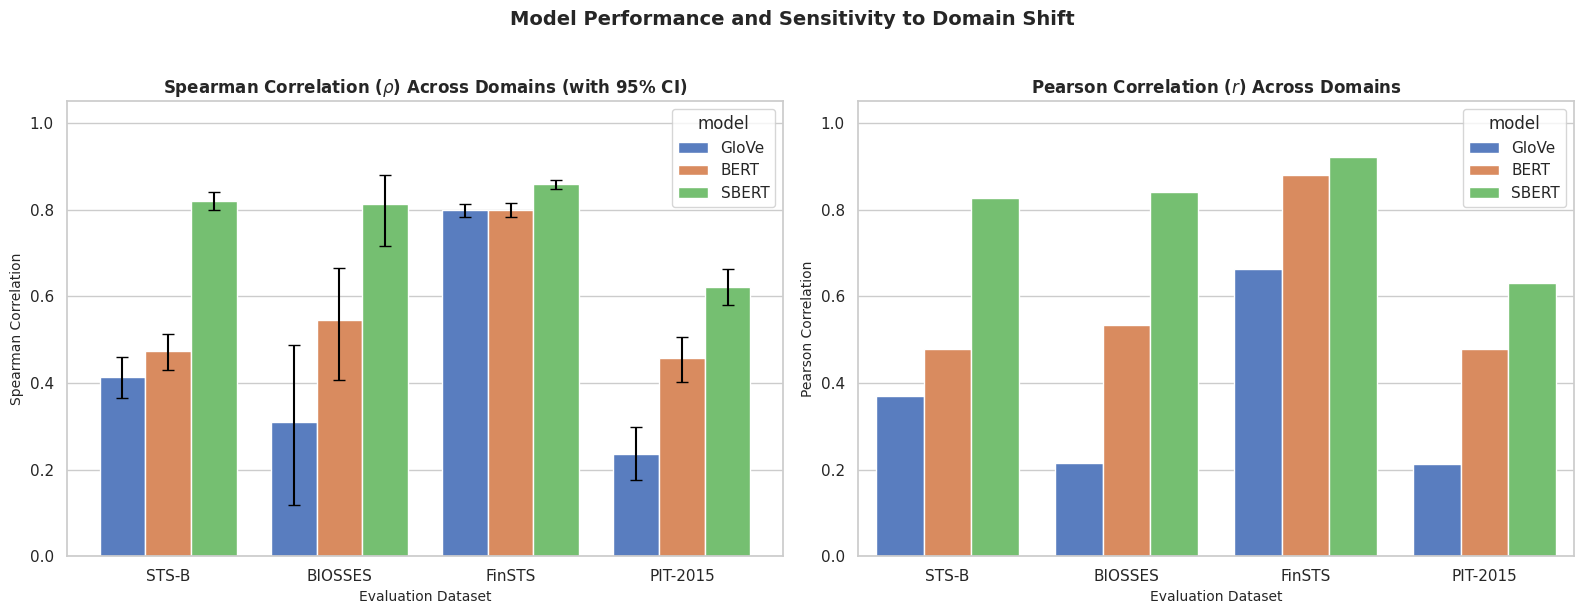

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configure plotting style
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Spearman Rank Correlation (Generalization Performance)
sns.barplot(
    data=zs,
    x="dataset",
    y="spearman",
    hue="model",
    ax=axes[0],
    palette="muted"
)

# Manually add the bootstrap confidence intervals as error bars
for i, bar in enumerate(axes[0].patches):
    if i >= len(zs):
        continue
    row = zs.iloc[i]
    # Get x coordinate of the bar center
    x = bar.get_x() + bar.get_width() / 2.0
    y = bar.get_height()
    # Draw error bar from ci_lo to ci_hi
    axes[0].errorbar(
        x=x,
        y=y,
        yerr=[[y - row['ci_lo']], [row['ci_hi'] - y]],
        fmt='none',
        color='black',
        capsize=4
    )

axes[0].set_title("Spearman Correlation ($\\rho$) Across Domains (with 95% CI)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Evaluation Dataset", fontsize=10)
axes[0].set_ylabel("Spearman Correlation", fontsize=10)
axes[0].set_ylim(0, 1.05)

# 2. Pearson Linear Correlation (Domain Shift Sensitivity)
sns.barplot(
    data=zs,
    x="dataset",
    y="pearson",
    hue="model",
    ax=axes[1],
    palette="muted"
)

axes[1].set_title("Pearson Correlation ($r$) Across Domains", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Evaluation Dataset", fontsize=10)
axes[1].set_ylabel("Pearson Correlation", fontsize=10)
axes[1].set_ylim(0, 1.05)

plt.suptitle("Model Performance and Sensitivity to Domain Shift", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### RQ2: Text Characteristics vs Embedding Performance
To answer this, we will calculate:
1. **Mean Sentence Length:** The average word count of the sentence pair.
2. **Length Difference:** The absolute difference in word counts between the two sentences.
3. **Vocabulary Overlap:** The Jaccard similarity of the words in the two sentences.

We will correlate these characteristics with the **absolute prediction error** of our best model (SBERT). A positive correlation means that as the feature increases, the model's error also increases (i.e., performance drops).

In [ ]:
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

def jaccard_overlap(s1, s2):
    set1 = set(str(s1).lower().split())
    set2 = set(str(s2).lower().split())
    if not set1 or not set2:
        return 0.0
    return len(set1.intersection(set2)) / len(set1.union(set2))

char_results = []
sbert_enc = ENCODERS['SBERT']

for dname, d in EVAL_SETS.items():
    df = d.to_pandas().rename(columns={"sentence1": "s1", "sentence2": "s2"})

    # Recalculate SBERT cosine similarities
    sims = pair_cosine(sbert_enc, df)

    # Calculate Text Characteristics
    df['len_s1'] = df['s1'].apply(lambda x: len(str(x).split()))
    df['len_s2'] = df['s2'].apply(lambda x: len(str(x).split()))
    df['mean_len'] = (df['len_s1'] + df['len_s2']) / 2.0
    df['len_diff'] = abs(df['len_s1'] - df['len_s2'])
    df['jaccard'] = df.apply(lambda row: jaccard_overlap(row['s1'], row['s2']), axis=1)

    # Absolute Prediction Error
    df['abs_error'] = abs(df['score'] - sims)

    # Rank Correlations (Spearman) with Absolute Error
    corr_len, _ = spearmanr(df['mean_len'], df['abs_error'])
    corr_diff, _ = spearmanr(df['len_diff'], df['abs_error'])
    corr_jaccard, _ = spearmanr(df['jaccard'], df['abs_error'])

    char_results.append({
        'Dataset': dname,
        'Domain': DOMAIN[dname],
        'Mean Length vs Error (ρ)': corr_len,
        'Length Diff vs Error (ρ)': corr_diff,
        'Vocab Overlap vs Error (ρ)': corr_jaccard
    })

char_df = pd.DataFrame(char_results)
display(char_df.round(3))

,Dataset,Domain,Mean Length vs Error (ρ),Length Diff vs Error (ρ),Vocab Overlap vs Error (ρ)
0,STS-B,general,-0.017,0.009,-0.122
1,BIOSSES,biomedical,-0.051,0.072,-0.113
2,FinSTS,financial,0.077,0.049,0.001
3,PIT-2015,social media,-0.233,-0.042,-0.158


### RQ3: Low-Resource Domain Adaptation
We will fine-tune SBERT on varying amounts of domain-specific sentence pairs (supervision) to see if and how much performance improves. We focus on the **Financial** (FinSTS) and **Social Media** (PIT-2015) domains, using their respective training/validation sets to fine-tune and testing on their test sets.

In [ ]:
!pip install -q peft "torchao>=0.16.0"

In [ ]:
import gc
import torch
import os
import time
from sentence_transformers import SentenceTransformer, InputExample, losses
from torch.utils.data import DataLoader
from scipy.stats import spearmanr
import pandas as pd
from datasets import load_from_disk

# Clear lingering models from previous evaluation steps to free GPU memory
if 'ENCODERS' in globals():
    del ENCODERS
if 'base_enc' in globals():
    del base_enc
if 'base_model' in globals():
    del base_model
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

# Ensure PERSIST_DIR is defined
try:
    PERSIST_DIR
except NameError:
    PERSIST_DIR = '/content/drive/MyDrive/COS802_STS'
    os.makedirs(PERSIST_DIR, exist_ok=True)

# Load datasets from Drive if missing from active runtime
try:
    PIT2015_norm
except NameError:
    print("Loading PIT2015_norm from Google Drive...")
    PIT2015_norm = load_from_disk(os.path.join(PERSIST_DIR, 'PIT2015_norm'))

try:
    FinSTS_norm
except NameError:
    print("Loading FinSTS_norm from Google Drive...")
    FinSTS_norm = load_from_disk(os.path.join(PERSIST_DIR, 'FinSTS_norm'))

# Change filename to force re-computation with resource tracking
rq3_results_path = os.path.join(PERSIST_DIR, 'rq3_results_high_res_resources.csv')

if os.path.exists(rq3_results_path):
    print(f"Loading previously computed RQ3 results with resources from {rq3_results_path}")
    rq3_df = pd.read_csv(rq3_results_path)
    display(rq3_df)
else:
    # Configure datasets for adaptation
    adapt_configs = [
        {"domain": "Social Media", "train_data": PIT2015_norm["train"], "test_data": PIT2015_norm["test"], "dataset_name": "PIT-2015"},
        {"domain": "Finance", "train_data": FinSTS_norm["validation"], "test_data": FinSTS_norm["test"], "dataset_name": "FinSTS"}
    ]

    adapt_models = {
        "BERT": BERT_NAME,
        "SBERT": SBERT_NAME
    }

    results_rq3 = []

    # Run at specific intervals up to 1000
    fast_adapt_sizes = [500,750, 1000, 1250, 1500,1750,2000]

    for model_alias, model_id in adapt_models.items():
        print(f"\n{'='*40}\nEvaluating Model: {model_alias}\n{'='*40}")

        for config in adapt_configs:
            print(f"\n--- Adapting {model_alias} for {config['domain']} ({config['dataset_name']}) ---")
            train_df = config['train_data'].to_pandas()
            test_df = config['test_data'].to_pandas().rename(columns={'sentence1': 's1', 'sentence2': 's2'})

            # 0-shot evaluation (Baseline)
            base_model = SentenceTransformer(model_id, device=str(DEVICE))
            base_model.max_seq_length = 256 # Cap sequence length
            base_enc = SBertEncoder(base_model)
            base_sims = pair_cosine(base_enc, test_df)
            base_rho, _ = spearmanr(test_df['score'], base_sims)

            results_rq3.append({
                'Model': model_alias,
                'Domain': config['domain'],
                'Train Size': 0,
                'Spearman': base_rho,
                'Training Time (s)': 0.0,
                'Peak GPU Memory (MB)': 0.0
            })
            print(f"  Zero-shot Spearman: {base_rho:.3f}")

            # Free baseline model
            del base_model, base_enc
            gc.collect()
            if torch.cuda.is_available(): torch.cuda.empty_cache()

            for size in fast_adapt_sizes:
                size_val = len(train_df) if size == "full" else size
                if isinstance(size_val, int) and size_val > len(train_df):
                    continue

                print(f"  Training on {size_val} samples...")
                sample_df = train_df.sample(n=size_val, random_state=SEED)

                train_examples = [
                    InputExample(texts=[row['sentence1'], row['sentence2']], label=float(row['score']))
                    for _, row in sample_df.iterrows()
                ]
                train_dataloader = DataLoader(train_examples, shuffle=True, batch_size=ADAPT_BS)

                # Reset GPU memory tracking
                if torch.cuda.is_available():
                    torch.cuda.reset_peak_memory_stats()

                start_time = time.time()

                # Initialize fresh model for each size to avoid cumulative learning
                model = SentenceTransformer(model_id, device=str(DEVICE))
                model.max_seq_length = 256 # Truncate long sequences strictly to avoid OOM
                train_loss = losses.CosineSimilarityLoss(model=model)

                model.fit(
                    train_objectives=[(train_dataloader, train_loss)],
                    epochs=ADAPT_EPOCHS,
                    warmup_steps=int(len(train_dataloader) * 0.1),
                    show_progress_bar=False,
                    optimizer_params={'lr': ADAPT_LR}
                )

                elapsed_time = time.time() - start_time
                peak_gpu_mem = torch.cuda.max_memory_allocated() / (1024 ** 2) if torch.cuda.is_available() else 0.0

                enc = SBertEncoder(model)
                sims = pair_cosine(enc, test_df)
                rho, _ = spearmanr(test_df['score'], sims)

                results_rq3.append({
                    'Model': model_alias,
                    'Domain': config['domain'],
                    'Train Size': size_val,
                    'Spearman': rho,
                    'Training Time (s)': elapsed_time,
                    'Peak GPU Memory (MB)': peak_gpu_mem
                })
                print(f"  -> Spearman: {rho:.3f} | Time: {elapsed_time:.1f}s | GPU Mem: {peak_gpu_mem:.1f}MB")

                # Fix RAM issue: explicitly delete model variables and clear CUDA cache
                del model, train_loss, enc, train_examples, train_dataloader
                gc.collect()
                if torch.cuda.is_available():
                    torch.cuda.empty_cache()

    rq3_df = pd.DataFrame(results_rq3)
    rq3_df.to_csv(rq3_results_path, index=False)
    print(f"\nSaved RQ3 results with resource usage stats to {rq3_results_path}")
    display(rq3_df)



Evaluating Model: BERT

--- Adapting BERT for Social Media (PIT-2015) ---


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  Zero-shot Spearman: 0.457
  Training on 500 samples...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


... (100 outputs left out)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Computing widget examples:   0%|          | 0/1 [00:00<?, ?example/s]

{'train_runtime': '66.42', 'train_samples_per_second': '90.33', 'train_steps_per_second': '5.646', 'train_loss': '0.01004', 'epoch': '3'}
  -> Spearman: 0.865 | Time: 70.5s | GPU Mem: 2645.1MB

Saved RQ3 results with resource usage stats to /content/drive/MyDrive/COS802_STS/rq3_results_high_res_resources.csv


,Model,Domain,Train Size,Spearman,Training Time (s),Peak GPU Memory (MB)
0,BERT,Social Media,0,0.456953,0.000000,0.000000
1,BERT,Social Media,500,0.411400,18.934664,3171.126953
2,BERT,Social Media,750,0.451758,27.019295,3170.531738
3,BERT,Social Media,1000,0.456053,34.437597,3172.803223
4,BERT,Social Media,1250,0.466387,41.546843,3171.126953
5,BERT,Social Media,1500,0.452574,48.758852,3168.609863
6,BERT,Social Media,1750,0.487248,56.600004,3174.831543
7,BERT,Social Media,2000,0.460364,63.531520,3169.190918
8,BERT,Finance,0,0.799565,0.000000,0.000000
9,BERT,Finance,500,0.827435,100.373890,7355.162598


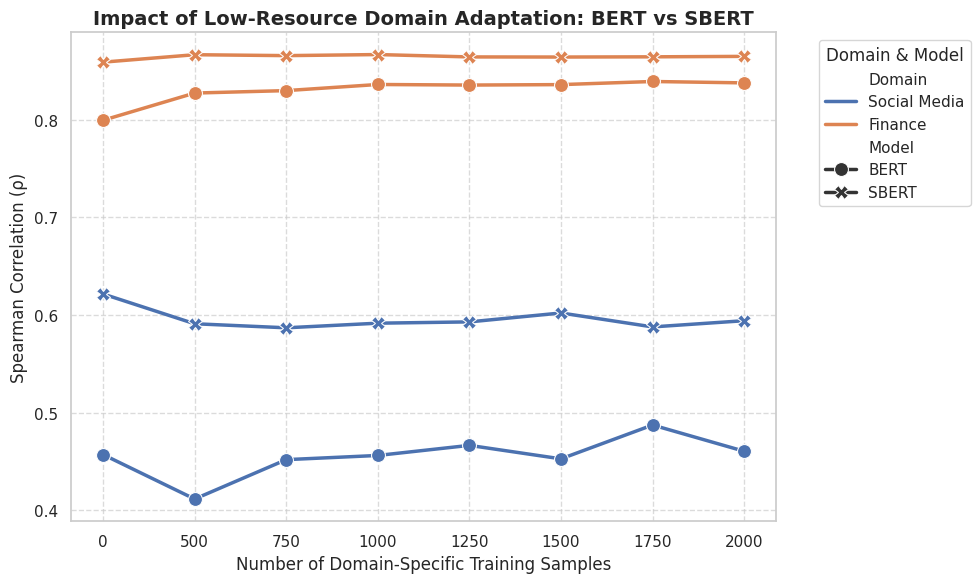

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

if 'rq3_df' in locals():
    # Sort by numeric size, then convert to string for evenly spaced categorical x-axis ticks
    plot_df = rq3_df.copy()
    plot_df = plot_df.sort_values(by='Train Size')
    plot_df['Train Size (Categorical)'] = plot_df['Train Size'].astype(str)

    plt.figure(figsize=(10, 6))
    sns.lineplot(
        data=plot_df,
        x='Train Size (Categorical)',
        y='Spearman',
        hue='Domain',
        style='Model',
        markers=True,
        dashes=False,
        linewidth=2.5,
        markersize=10,
        sort=False # Preserves the numeric sorting we did above
    )

    plt.title('Impact of Low-Resource Domain Adaptation: BERT vs SBERT', fontsize=14, fontweight='bold')
    plt.xlabel('Number of Domain-Specific Training Samples', fontsize=12)
    plt.ylabel('Spearman Correlation (ρ)', fontsize=12)
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.legend(title='Domain & Model', bbox_to_anchor=(1.05, 1), loc='upper left')

    plt.tight_layout()
    plt.show()
else:
    print("Error: rq3_df is not defined. Please ensure the previous training cell completes successfully.")


### RQ3.5: Parameter-Efficient Fine-Tuning (LoRA)
Here, we introduce **LoRA (Low-Rank Adaptation)** to see if training fewer parameters yields better stability and performance on small datasets compared to full fine-tuning. We will apply LoRA to the SBERT model and compare it against the previously collected results.

In [ ]:
import os
import gc
import torch
import time
import pandas as pd
from torch.utils.data import DataLoader
from sentence_transformers import SentenceTransformer, models, InputExample, losses
from scipy.stats import spearmanr
from peft import LoraConfig, get_peft_model
from datasets import load_from_disk

# Ensure PERSIST_DIR is defined
try:
    PERSIST_DIR
except NameError:
    PERSIST_DIR = '/content/drive/MyDrive/COS802_STS'
    os.makedirs(PERSIST_DIR, exist_ok=True)

# Load datasets from Drive if missing from active runtime
try:
    PIT2015_norm
except NameError:
    print("Loading PIT2015_norm from Google Drive...")
    PIT2015_norm = load_from_disk(os.path.join(PERSIST_DIR, 'PIT2015_norm'))

try:
    FinSTS_norm
except NameError:
    print("Loading FinSTS_norm from Google Drive...")
    FinSTS_norm = load_from_disk(os.path.join(PERSIST_DIR, 'FinSTS_norm'))

# Change filename to force re-computation with resource tracking
lora_results_path = os.path.join(PERSIST_DIR, 'lora_results_high_res_resources.csv')
FORCE_RECOMPUTE = True # Force re-running to include the sizes up to 2000

if os.path.exists(lora_results_path) and not FORCE_RECOMPUTE:
    print(f"Loading previously computed LoRA results with resources from {lora_results_path}")
    lora_df = pd.read_csv(lora_results_path)
    display(lora_df)
else:
    lora_results = []
    fast_adapt_sizes = [500,750, 1000, 1250, 1500,1750,2000]

    adapt_configs = [
        {"domain": "Social Media", "train_data": PIT2015_norm["train"], "test_data": PIT2015_norm["test"], "dataset_name": "PIT-2015"},
        {"domain": "Finance", "train_data": FinSTS_norm["validation"], "test_data": FinSTS_norm["test"], "dataset_name": "FinSTS"}
    ]

    adapt_models = {
        "BERT": BERT_NAME,
        "SBERT": SBERT_NAME
    }

    print("Evaluating LoRA Fine-Tuning for BERT & SBERT...")

    for model_alias, model_id in adapt_models.items():
        print(f"\n{'='*40}\nEvaluating LoRA for Model: {model_alias}\n{'='*40}")
        for config in adapt_configs:
            print(f"\n--- LoRA Adapting {model_alias} for {config['domain']} ---")
            train_df = config['train_data'].to_pandas()
            test_df = config['test_data'].to_pandas().rename(columns={'sentence1': 's1', 'sentence2': 's2'})

            # Load or calculate zero-shot score
            try:
                zero_shot_score = rq3_df[(rq3_df['Model'] == model_alias) & (rq3_df['Domain'] == config['domain']) & (rq3_df['Train Size'] == 0)]['Spearman'].values[0]
            except Exception:
                base_model = SentenceTransformer(model_id, device=str(DEVICE))
                base_enc = SBertEncoder(base_model)
                base_sims = pair_cosine(base_enc, test_df)
                zero_shot_score, _ = spearmanr(test_df['score'], base_sims)
                del base_model, base_enc

            lora_results.append({
                'Model': model_alias,
                'Domain': config['domain'],
                'Train Size': 0,
                'Spearman': zero_shot_score,
                'Method': 'LoRA',
                'Training Time (s)': 0.0,
                'Peak GPU Memory (MB)': 0.0
            })
            print(f"  Zero-shot Spearman: {zero_shot_score:.3f}")

            for size_val in fast_adapt_sizes:
                print(f"  Training on {size_val} samples...")
                sample_df = train_df.sample(n=size_val, random_state=SEED)

                train_examples = [
                    InputExample(texts=[row['sentence1'], row['sentence2']], label=float(row['score']))
                    for _, row in sample_df.iterrows()
                ]
                train_dataloader = DataLoader(train_examples, shuffle=True, batch_size=ADAPT_BS)

                # Reset GPU memory tracking
                if torch.cuda.is_available():
                    torch.cuda.reset_peak_memory_stats()

                start_time = time.time()

                # Initialize LoRA with fully qualified repo name
                hf_repo_name = "sentence-transformers/all-MiniLM-L6-v2" if model_id == "all-MiniLM-L6-v2" else model_id
                transformer = models.Transformer(hf_repo_name)

                # target_modules for BERT/MiniLM architecture
                lora_config = LoraConfig(
                    r=8,
                    lora_alpha=16,
                    target_modules=["query", "value"],
                    lora_dropout=0.05,
                    bias="none",
                    task_type="FEATURE_EXTRACTION"
                )

                # Wrap the base model with LoRA
                transformer.auto_model = get_peft_model(transformer.auto_model, lora_config)
                pooling = models.Pooling(transformer.get_word_embedding_dimension())
                model = SentenceTransformer(modules=[transformer, pooling], device=str(DEVICE))

                train_loss = losses.CosineSimilarityLoss(model=model)

                # Note: LoRA usually requires a slightly higher learning rate than full fine-tuning
                model.fit(
                    train_objectives=[(train_dataloader, train_loss)],
                    epochs=ADAPT_EPOCHS,
                    warmup_steps=int(len(train_dataloader) * 0.1),
                    show_progress_bar=False,
                    optimizer_params={'lr': ADAPT_LR * 10}
                )

                elapsed_time = time.time() - start_time
                peak_gpu_mem = torch.cuda.max_memory_allocated() / (1024 ** 2) if torch.cuda.is_available() else 0.0

                # Evaluate
                enc = SBertEncoder(model)
                sims = pair_cosine(enc, test_df)
                rho, _ = spearmanr(test_df['score'], sims)

                lora_results.append({
                    'Model': model_alias,
                    'Domain': config['domain'],
                    'Train Size': size_val,
                    'Spearman': rho,
                    'Method': 'LoRA',
                    'Training Time (s)': elapsed_time,
                    'Peak GPU Memory (MB)': peak_gpu_mem
                })
                print(f"  -> Spearman: {rho:.3f} | Time: {elapsed_time:.1f}s | GPU Mem: {peak_gpu_mem:.1f}MB")

                # Cleanup memory
                del model, train_loss, enc, train_examples, train_dataloader, transformer, pooling
                gc.collect()
                if torch.cuda.is_available():
                    torch.cuda.empty_cache()

    lora_df = pd.DataFrame(lora_results)
    lora_df.to_csv(lora_results_path, index=False)
    display(lora_df)


Evaluating LoRA Fine-Tuning for BERT & SBERT...

Evaluating LoRA for Model: BERT

--- LoRA Adapting BERT for Social Media ---
  Zero-shot Spearman: 0.457
  Training on 500 samples...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Computing widget examples:   0%|          | 0/1 [00:00<?, ?example/s]

{'train_runtime': '8.635', 'train_samples_per_second': '173.7', 'train_steps_per_second': '11.12', 'train_loss': '0.1211', 'epoch': '3'}
  -> Spearman: 0.406 | Time: 12.2s | GPU Mem: 1088.4MB
  Training on 750 samples...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

... (90 outputs left out)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Computing widget examples:   0%|          | 0/1 [00:00<?, ?example/s]

{'train_runtime': '59.3', 'train_samples_per_second': '101.2', 'train_steps_per_second': '6.324', 'train_loss': '0.01488', 'epoch': '3'}
  -> Spearman: 0.865 | Time: 61.5s | GPU Mem: 2224.6MB


,Model,Domain,Train Size,Spearman,Method,Training Time (s),Peak GPU Memory (MB)
0,BERT,Social Media,0,0.456953,LoRA,0.000000,0.000000
1,BERT,Social Media,500,0.405950,LoRA,12.225087,1088.443848
2,BERT,Social Media,750,0.405637,LoRA,16.528893,1059.652832
3,BERT,Social Media,1000,0.433601,LoRA,21.520658,1059.652832
4,BERT,Social Media,1250,0.429159,LoRA,25.546868,1039.365234
5,BERT,Social Media,1500,0.438343,LoRA,29.503567,1059.652832
6,BERT,Social Media,1750,0.453765,LoRA,34.057240,1059.652832
7,BERT,Social Media,2000,0.459467,LoRA,38.148962,1050.990234
8,BERT,Finance,0,0.799565,LoRA,0.000000,0.000000
9,BERT,Finance,500,0.799321,LoRA,81.663828,6784.426758


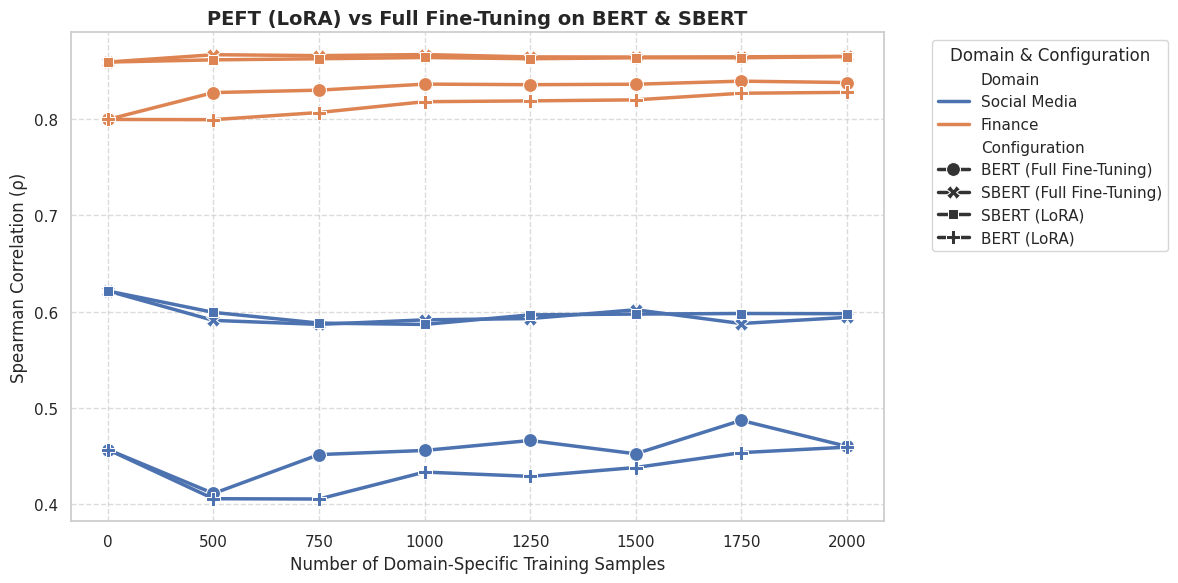

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

if 'lora_df' in locals() and 'rq3_df' in locals():
    # Get Full FT results for both models
    full_ft = rq3_df.copy()
    full_ft['Method'] = 'Full Fine-Tuning'

    # Combine
    plot_df = pd.concat([full_ft, lora_df])
    plot_df = plot_df.sort_values(by='Train Size')
    plot_df['Train Size (Categorical)'] = plot_df['Train Size'].astype(str)
    plot_df['Configuration'] = plot_df['Model'] + ' (' + plot_df['Method'] + ')'

    plt.figure(figsize=(12, 6))
    sns.lineplot(
        data=plot_df,
        x='Train Size (Categorical)',
        y='Spearman',
        hue='Domain',
        style='Configuration',
        markers=True,
        dashes=False,
        linewidth=2.5,
        markersize=10,
        sort=False
    )

    plt.title('PEFT (LoRA) vs Full Fine-Tuning on BERT & SBERT', fontsize=14, fontweight='bold')
    plt.xlabel('Number of Domain-Specific Training Samples', fontsize=12)
    plt.ylabel('Spearman Correlation (ρ)', fontsize=12)
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.legend(title='Domain & Configuration', bbox_to_anchor=(1.05, 1), loc='upper left')

    plt.tight_layout()
    plt.show()
else:
    print("Make sure both the Full Fine-tuning cell and LoRA cell ran successfully.")


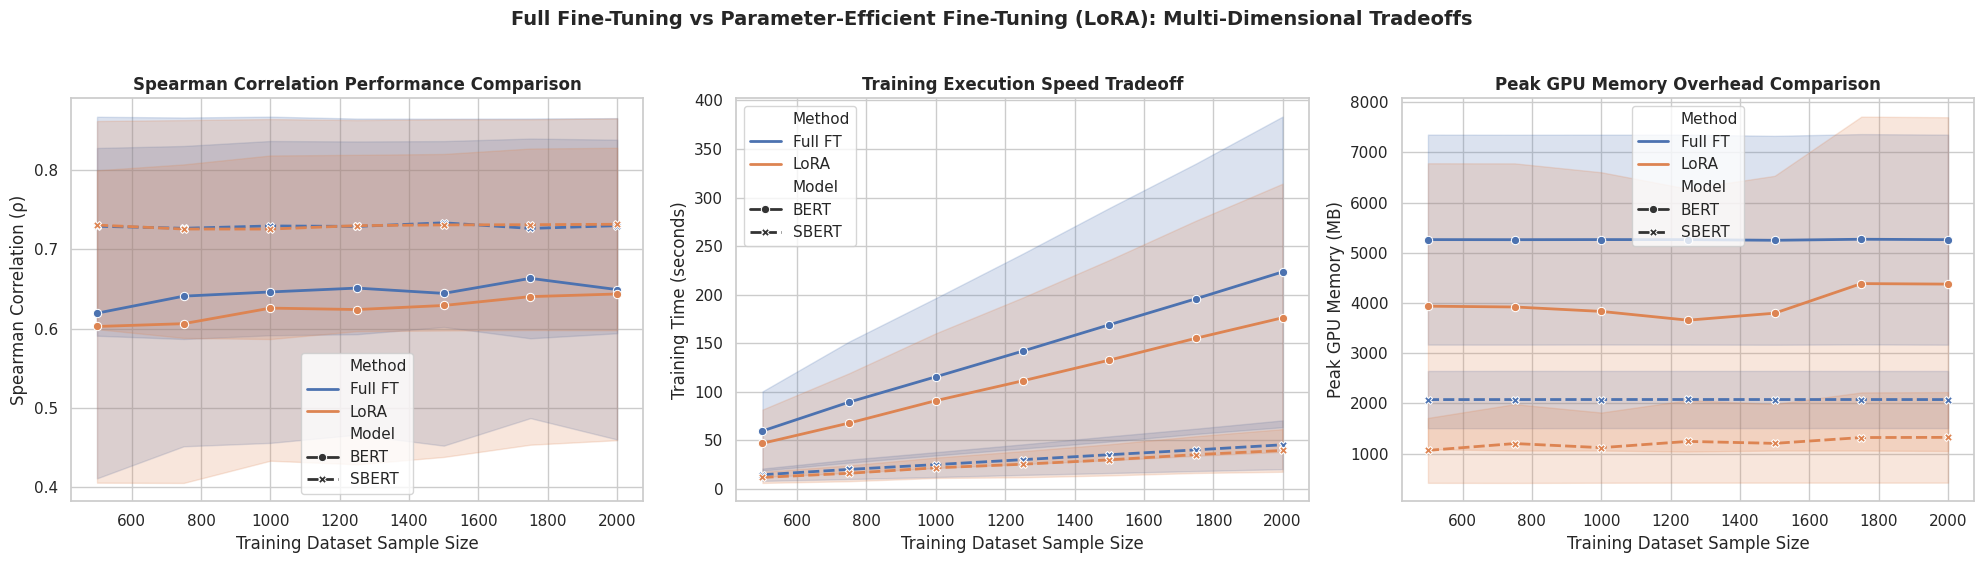

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import os

try:
    PERSIST_DIR
except NameError:
    PERSIST_DIR = '/content/drive/MyDrive/COS802_STS'

rq3_res_path = os.path.join(PERSIST_DIR, 'rq3_results_high_res_resources.csv')
lora_res_path = os.path.join(PERSIST_DIR, 'lora_results_high_res_resources.csv')

if os.path.exists(rq3_res_path) and os.path.exists(lora_res_path):
    df_ft = pd.read_csv(rq3_res_path)
    df_ft['Method'] = 'Full FT'

    df_lora = pd.read_csv(lora_res_path)
    df_lora['Method'] = 'LoRA'

    df_all = pd.concat([df_ft, df_lora], ignore_index=True)
    df_all = df_all[df_all['Train Size'] > 0] # Focus on active training steps

    fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
    sns.set_theme(style='whitegrid')

    # Plot 1: Spearman vs Sample Size
    sns.lineplot(data=df_all, x='Train Size', y='Spearman', hue='Method', style='Model', markers=True, ax=axes[0], linewidth=2)
    axes[0].set_title('Spearman Correlation Performance Comparison', fontweight='bold')
    axes[0].set_xlabel('Training Dataset Sample Size')
    axes[0].set_ylabel('Spearman Correlation (ρ)')

    # Plot 2: Elapsed Training Time vs Sample Size
    sns.lineplot(data=df_all, x='Train Size', y='Training Time (s)', hue='Method', style='Model', markers=True, ax=axes[1], linewidth=2)
    axes[1].set_title('Training Execution Speed Tradeoff', fontweight='bold')
    axes[1].set_xlabel('Training Dataset Sample Size')
    axes[1].set_ylabel('Training Time (seconds)')

    # Plot 3: Peak GPU Memory Allocation vs Sample Size
    sns.lineplot(data=df_all, x='Train Size', y='Peak GPU Memory (MB)', hue='Method', style='Model', markers=True, ax=axes[2], linewidth=2)
    axes[2].set_title('Peak GPU Memory Overhead Comparison', fontweight='bold')
    axes[2].set_xlabel('Training Dataset Sample Size')
    axes[2].set_ylabel('Peak GPU Memory (MB)')

    plt.suptitle('Full Fine-Tuning vs Parameter-Efficient Fine-Tuning (LoRA): Multi-Dimensional Tradeoffs', y=1.02, fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()
else:
    print('Resource CSV files not found. Please verify that the training sweeps ran successfully and produced the files.')

In [ ]:
import os
import pandas as pd

PERSIST_DIR = '/content/drive/MyDrive/COS802_STS'
rq3_results_path = os.path.join(PERSIST_DIR, 'rq3_results_high_res_resources.csv')
lora_results_path = os.path.join(PERSIST_DIR, 'lora_results_high_res_resources.csv')

# Load results into memory if they exist
if os.path.exists(rq3_results_path):
    print("Loading RQ3 results...")
    rq3_df = pd.read_csv(rq3_results_path)
    display(rq3_df.head())
else:
    print("RQ3 results file not found at:", rq3_results_path)

if os.path.exists(lora_results_path):
    print("Loading LoRA results...")
    lora_df = pd.read_csv(lora_results_path)
    display(lora_df.head())
else:
    print("LoRA results file not found at:", lora_results_path)

Loading RQ3 results...


,Model,Domain,Train Size,Spearman,Training Time (s),Peak GPU Memory (MB)
0,BERT,Social Media,0,0.456953,0.000000,0.000000
1,BERT,Social Media,500,0.411400,18.934664,3171.126953
2,BERT,Social Media,750,0.451758,27.019295,3170.531738
3,BERT,Social Media,1000,0.456053,34.437597,3172.803223
4,BERT,Social Media,1250,0.466387,41.546843,3171.126953


Loading LoRA results...


,Model,Domain,Train Size,Spearman,Method,Training Time (s),Peak GPU Memory (MB)
0,BERT,Social Media,0,0.456953,LoRA,0.000000,0.000000
1,BERT,Social Media,500,0.405950,LoRA,12.225087,1088.443848
2,BERT,Social Media,750,0.405637,LoRA,16.528893,1059.652832
3,BERT,Social Media,1000,0.433601,LoRA,21.520658,1059.652832
4,BERT,Social Media,1250,0.429159,LoRA,25.546868,1039.365234


In [ ]:
import os
import pandas as pd

PERSIST_DIR = '/content/drive/MyDrive/COS802_STS'

if os.path.exists(PERSIST_DIR):
    files = os.listdir(PERSIST_DIR)
    print("Files found in Google Drive directory:", files)

    # Attempt to load any CSV results we find
    for file in files:
        if file.endswith('.csv'):
            file_path = os.path.join(PERSIST_DIR, file)
            print(f"\nLoading {file}...")
            df = pd.read_csv(file_path)
            display(df.head())

            # Register the global variables for the notebook
            if 'rq3' in file.lower():
                rq3_df = df
                print("Registered as global variable: rq3_df")
            elif 'lora' in file.lower():
                lora_df = df
                print("Registered as global variable: lora_df")
else:
    print(f"The directory {PERSIST_DIR} does not exist.")

Files found in Google Drive directory: ['PIT2015_norm', 'STSB_norm', 'BIOSSES_norm', 'FinSTS_norm', 'finetuned_BERT_PIT-2015_100', 'finetuned_BERT_PIT-2015_500', 'finetuned_BERT_PIT-2015_1000', 'finetuned_BERT_FinSTS_100', 'finetuned_BERT_FinSTS_500', 'finetuned_BERT_FinSTS_1000', 'finetuned_SBERT_PIT-2015_100', 'finetuned_SBERT_PIT-2015_500', 'finetuned_SBERT_PIT-2015_1000', 'finetuned_SBERT_FinSTS_100', 'finetuned_SBERT_FinSTS_500', 'finetuned_SBERT_FinSTS_1000', 'rq3_results.csv', 'lora_results.csv', 'lora_results_all.csv', 'rq3_results_high_res_resources.csv', 'lora_results_high_res_resources.csv']

Loading rq3_results.csv...


,Model,Domain,Train Size,Spearman
0,BERT,Social Media,0,0.456953
1,BERT,Social Media,100,0.419670
2,BERT,Social Media,500,0.415909
3,BERT,Social Media,1000,0.443046
4,BERT,Finance,0,0.799603


Registered as global variable: rq3_df

Loading lora_results.csv...


,Domain,Train Size,Spearman,Method
0,Social Media,0,0.621520,LoRA
1,Social Media,100,0.625126,LoRA
2,Social Media,500,0.632589,LoRA
3,Social Media,1000,0.591012,LoRA
4,Finance,0,0.859101,LoRA


Registered as global variable: lora_df

Loading lora_results_all.csv...


,Model,Domain,Train Size,Spearman,Method
0,BERT,Social Media,0,0.456953,LoRA
1,BERT,Social Media,100,0.455461,LoRA
2,BERT,Social Media,500,0.390169,LoRA
3,BERT,Social Media,1000,0.402123,LoRA
4,BERT,Finance,0,0.799603,LoRA


Registered as global variable: lora_df

Loading rq3_results_high_res_resources.csv...


,Model,Domain,Train Size,Spearman,Training Time (s),Peak GPU Memory (MB)
0,BERT,Social Media,0,0.456953,0.000000,0.000000
1,BERT,Social Media,500,0.411400,18.934664,3171.126953
2,BERT,Social Media,750,0.451758,27.019295,3170.531738
3,BERT,Social Media,1000,0.456053,34.437597,3172.803223
4,BERT,Social Media,1250,0.466387,41.546843,3171.126953


Registered as global variable: rq3_df

Loading lora_results_high_res_resources.csv...


,Model,Domain,Train Size,Spearman,Method,Training Time (s),Peak GPU Memory (MB)
0,BERT,Social Media,0,0.456953,LoRA,0.000000,0.000000
1,BERT,Social Media,500,0.405950,LoRA,12.225087,1088.443848
2,BERT,Social Media,750,0.405637,LoRA,16.528893,1059.652832
3,BERT,Social Media,1000,0.433601,LoRA,21.520658,1059.652832
4,BERT,Social Media,1250,0.429159,LoRA,25.546868,1039.365234


Registered as global variable: lora_df
